# House Prices: Algorithms and Data Workflow

DSAI4204 Data Mining & Data Warehousing

## Repository

Maintained by [liuruizekevin](https://github.com/liuruizekevin)


## Overview

This Notebook accompanies the House Prices report. Part A explains the algorithms and prediction procedure; Part B walks through the data checks, feature preparation, prediction calculation and validation.

The selected model combines **64% raw TabPFN, 16% domain TabPFN and 20% TabICL** in natural-log price space. The preserved submitted CSV scored **0.10970** on Kaggle. The workflow uses all **1,460 training houses** and **1,459 test houses**.

### Reading and running the Notebook

GitHub Preview displays the saved tables and four EDA figures. To run the cells, use Python 3.12 with the packages in `requirements.txt`. From the repository root, prepare the workspace:

```sh
python3 code/notebook/prepare.py --prepare
```

Open `outputs/notebook/notebooks/house_prices.ipynb` with that Python environment, then run Part B in order. The preparation command copies the required files using their canonical repository paths. If that output folder already contains a different version, choose a new workspace with `--output outputs/notebook_run`.

The default run uses saved component predictions and writes a recomputed CSV to `outputs/predictions.csv` inside the prepared workspace. The exact scored CSV is kept separately.


## Contents

- Part A. Algorithms and final prediction procedure
  - A.1 Classical estimators and their roles
  - A.2 Inputs and the deterministic domain map
  - A.3 The three pretrained branches
  - A.4 Final prediction algorithm and log-space combination
  - A.5 Out-of-fold evaluation and saved-prediction checks
  - A.6 External algorithm references
- Part B. Data and saved prediction workflow
  - B.1 Environment and imports
  - B.2 Data provenance and exact inputs
  - B.3 Exploratory data analysis
  - B.4 Deterministic feature handoff
  - B.5 Selected model and prediction settings
  - B.6 Generate predictions
  - B.7 Validate the final model result
  - B.8 Interpreting the saved checks


## Part A. Algorithms and final prediction procedure

Part A specifies the algorithms used in groups A-K and the selected three-component prediction procedure. It expands the report with objectives, feature definitions, inference equations and validation steps. The selected configuration retains all 1,460 labeled houses and predicts the 1,459 competition test houses. The following notation distinguishes model branches from the experiment labels A-K.


### A.1 Classical estimators and their roles

Let $u_i$ be a processed feature vector. The target $t_i$ is dollar SalePrice for Group A and natural-log SalePrice for B-G. Ridge fits an intercept $b$ and coefficient vector $\beta$ by minimizing the regularized squared-error objective [A1]:

$$
\min_{b,\beta}\;\sum_i(t_i-b-u_i^\top\beta)^2+\alpha\lVert\beta\rVert_2^2,\qquad\alpha=20.
$$

The intercept is not penalized. A-E retain this penalty strength while changing the target or preprocessing. Numeric standardization gives coefficient shrinkage a comparable meaning across units. Ridge is linear in its supplied columns: an area sum gives a compact representation, while explicit quality-area products add interaction terms. The initial one-hot pipelines fit remaining imputation, category vocabularies and scaling on training folds only.

CatBoost and XGBoost form additive tree ensembles [A2,A3]. Writing $h_m$ for the new tree and $\eta$ for its learning rate, their prediction has the form

$$
f_m(u)=f_{m-1}(u)+\eta h_m(u).
$$

Each tree partitions feature space and assigns a value to each leaf. This allows the effect of area, age or quality to vary with other feature conditions. Tree depth, learning rate and regularization restrict complexity. XGBoost evaluates updates using first- and second-order loss derivatives with a tree-complexity penalty. Group F uses one-hot CatBoost with depth 5, 1,100 trees, learning rate 0.035, L2 leaf penalty 5 and RMSE loss. Group G uses a separately fitted native-categorical CatBoost with MAE loss, an RBF SVR and XGBoost, combined in log space with weights 0.4/0.4/0.2.

For epsilon-insensitive support vector regression, $\psi$ denotes the implicit kernel feature map [A1]:

$$
\min_{w,b,\xi,\xi^*}\;\frac12\lVert w\rVert^2+C\sum_i(\xi_i+\xi_i^*),\quad
\begin{cases}
t_i-w^\top\psi(u_i)-b\le\epsilon+\xi_i,\\
w^\top\psi(u_i)+b-t_i\le\epsilon+\xi_i^*,\\
\xi_i,\xi_i^*\ge0.
\end{cases}
$$

G uses $C=10$, $\epsilon=0.008$ and the radial-basis kernel $k(u,v)=\exp(-0.001\lVert u-v\rVert^2)$. The slack variables penalize errors beyond epsilon; the kernel supplies nonlinear similarity without explicitly constructing every interaction. Fold-fitted scaling and predictor skew correction determine these distances. Support vectors define the fitted prediction function.



### A.2 Inputs and the deterministic domain map

For the selected model, write $\mathcal D_T=\{(x_i,z_i):i\in T\}$ with $z_i=\ln(\mathrm{SalePrice}_i)$. Id identifies rows and is excluded from predictors. Raw TabPFN and TabICL receive the 79 original columns. The domain TabPFN branch receives $\phi(x)$: 79 originals, ten engineered features and nine numeric missingness indicators, for 98 columns before internal encoding. No final training-row filter is applied.

CSV loading treats NA and blank fields as missing and preserves the valid literal category None. In the domain branch, MSSubClass is categorical. Absent Alley and Fence values become None. For pool, fireplace, miscellaneous feature, garage, basement and masonry groups, a missing descriptor becomes Unknown when its associated size/count is positive, and None otherwise. Thus an absent amenity and an existing amenity with unknown details remain distinct.

The nine missingness flags cover MasVnrArea, BsmtFinSF1, BsmtFinSF2, BsmtUnfSF, TotalBsmtSF, BsmtFullBath, BsmtHalfBath, GarageCars and GarageArea. Each flag records missingness before the corresponding numeric entry is set to zero. Other missing inputs remain for model-internal processing. Let $v(c)$ denote numeric conversion of field $c$ with missing/unparseable values replaced by zero when forming derived quantities, and $[a]_+=\max(a,0)$.

| Domain feature | Definition |
| --- | --- |
| TotalSF | $v(\mathrm{TotalBsmtSF})+v(\mathrm{1stFlrSF})+v(\mathrm{2ndFlrSF})$ |
| TotalFinishedSF | $v(\mathrm{GrLivArea})+v(\mathrm{BsmtFinSF1})+v(\mathrm{BsmtFinSF2})$ |
| HouseAge | $[v(\mathrm{YrSold})-v(\mathrm{YearBuilt})]_+$ |
| RemodelAge | $[v(\mathrm{YrSold})-v(\mathrm{YearRemodAdd})]_+$ |
| GarageAge | $[v(\mathrm{YrSold})-v(\mathrm{GarageYrBlt})]_+$ if the garage year is positive; otherwise zero |
| WasRemodeled | $\mathbf1\{v(\mathrm{YearRemodAdd})\ne v(\mathrm{YearBuilt})\}$ |
| TotalBath | $v(\mathrm{FullBath})+0.5v(\mathrm{HalfBath})+v(\mathrm{BsmtFullBath})+0.5v(\mathrm{BsmtHalfBath})$ |
| TotalPorchSF | Sum of OpenPorchSF, EnclosedPorch, 3SsnPorch, ScreenPorch and WoodDeckSF under $v$ |
| QualityLivingArea | $v(\mathrm{OverallQual})v(\mathrm{GrLivArea})$ |
| QualityTotalSF | $v(\mathrm{OverallQual})\,\mathrm{TotalSF}$ |

All original predictors remain. These features depend only on the same house, while learned preprocessing is fitted on the training partition. Missingness indicators preserve information lost by deterministic zero filling. The two raw branches use their own internal encoders; they do not inherit the domain map or the earlier Ridge preprocessing pipeline.



### A.3 The three pretrained branches

TabPFN and TabICLv2 are pretrained on synthetic tabular tasks [A4,A7]. This project loads released checkpoints. Fitting supplies training-partition preprocessing and labeled context; prediction performs in-context inference. The current final branches are:

| Branch | Inputs and inference settings | Log weight |
| --- | --- | --- |
| Raw/noY TabPFN | 79 predictors; original-v2 checkpoints; 16 total members over three checkpoints, allocated 6/5/5; no extra target power transform | 0.64 |
| Domain TabPFN | 98 predictors from $\phi$; one original-v2 checkpoint; 32 members with identity/safe-power target views | 0.16 |
| TabICLv2 | 79 predictors; eight members; none/power input normalization, Latin feature permutations and batch size 8 | 0.20 |

All branches use model seed 42 and Apple MPS. TabPFN uses package 9.2.0; its v2 checkpoint generation is a separate identifier. TabICL uses package 2.2.0 and the released v2 regression checkpoint. The branch member counts describe inference views. Group H uses a separate 32-member, one-checkpoint raw TabPFN configuration; it is not the raw/noY branch in J and K.

For the two TabPFN branches, the supplied log target is standardized within training index set $T$ [A6]:

$$
\mu_T=\frac1{|T|}\sum_{i\in T}z_i,\qquad
\sigma_T=\sqrt{\frac1{|T|}\sum_{i\in T}(z_i-\mu_T)^2}+10^{-20},\qquad
u_i=\frac{z_i-\mu_T}{\sigma_T}.
$$

The raw/noY branch retains this normalization and the external logarithm. It disables only the additional target power map. The domain branch retains identity and safely implemented Yeo-Johnson target transformations, with parameters learned on training targets. Its 32 inference members combine 16 identity and 16 safe-power target views with the configured input preprocessing. Raw/noY uses the identity target view across its three checkpoints [A5,A6].

For branch $j$ and inference member $e$, let $P_{je}$ be its fitted input map and $T_{je}$ its target map. The checkpoint model conditions on $(P_{je}(x_i),T_{je}(u_i))$ for $i\in T$ and returns target-bin logits $\ell_{jek}$. For the original v2 settings, the softmax temperature is 0.9:

$$
p_{jek}(x)=\frac{\exp(\ell_{jek}(x)/0.9)}{\sum_r\exp(\ell_{jer}(x)/0.9)},\qquad
\overline p_{jk}(x)=\frac1{M_j}\sum_{e=1}^{M_j}\mathcal R_{je}(p_{je})_k.
$$

The operation $\mathcal R_{je}$ inverse-transforms target-bin borders, handles invalid borders and transfers probability mass to a common normalized-target grid. With $m_k$ the bin's conditional mean, the returned prediction is

$$
f_j(x;\mathcal D_T)=\mu_T+\sigma_T\sum_k m_k\overline p_{jk}(x),\qquad
M_{\rm raw}=16,\quad M_{\rm domain}=32.
$$

This averages aligned probabilities before taking the mean, because average_before_softmax is false. Interior bins use their midpoint means; the two unbounded tails use the full-support distribution's half-normal conditional means. Inverse-transforming a scalar mean alone would not reproduce this distribution transformation [A6]. For the domain branch, $x$ in these expressions means $\phi(x)$.

TabICLv2 fits its internal encoder, input transformations and target StandardScaler on the training subset. Each normalized/permuted inference view gives a predictive distribution on standardized log target $U$. With fitted mean $\mu_C$ and scale $s_C$, its selected mean output is summarized by

$$
g(x;\mathcal D_T)=\mu_C+s_C\frac18\sum_{e=1}^{8}\mathbb E_{q_e}[U\mid x,\mathcal D_T].
$$

The output is restored to the supplied log-price scale before outer blending. These transformations and prediction contexts use the corresponding training partition. Input outlier handling does not remove training rows [A8].



### A.4 Final prediction algorithm and log-space combination

Let $f_{\rm raw}$, $f_{\rm domain}$ and $g$ be the three log-price predictions. The J anchor and selected K model are

$$
\begin{aligned}
f_J(x)&=0.80f_{\rm raw}(x)+0.20f_{\rm domain}(\phi(x)),\\
\widehat z_K(x)&=0.80f_J(x)+0.20g(x)\\
&=0.64f_{\rm raw}(x)+0.16f_{\rm domain}(\phi(x))+0.20g(x),\\
\widehat y_K(x)&=\exp\bigl(\widehat z_K(x)\bigr).
\end{aligned}
$$

The final dollar prediction is therefore a weighted geometric mean. The same configured weights apply to every house. No additional bias correction or clipping is applied after the blend. The following pseudocode specifies prediction from a training context; the saved-output calculation in Part B applies its final aggregation to the retained component predictions.

```text
Algorithm A1: three-branch prediction from a labeled context
Input: labeled training rows D_T; query rows Q with output IDs
1. Exclude Id from model inputs; set training target z = ln(SalePrice).
2. Prepare raw predictors X_T and X_Q with the stated missing-value policy.
3. Compute the row-local domain views phi(X_T) and phi(X_Q).
4. For each branch (raw/noY TabPFN, domain TabPFN, TabICLv2):
     load the fixed checkpoint(s) and recorded inference settings;
     fit branch-specific preprocessing and labeled context on D_T;
     predict the mean log target for Q; retain the original query order.
5. Require aligned IDs and finite log predictions across all branches.
6. z_Q = 0.64 * raw_Q + 0.16 * domain_Q + 0.20 * tabicl_Q.
7. price_Q = exp(z_Q); require finite positive prices and unique IDs.
Output: the Id, SalePrice table in the official query order.
```

For aligned component errors $e_J=f_J-z$ and $e_C=g-z$, averaging over the same evaluated houses gives the exact identity

$$
\overline{e_K^2}=0.64\,\overline{e_J^2}+0.04\,\overline{e_C^2}+0.32\,\overline{e_Je_C}.
$$

The cross-error term explains why complementary errors can improve the mixture. Architectural differences alone do not guarantee improvement. The main-text comparison evaluates the actual J-to-K change on paired folds. Development results and Kaggle feedback informed selection; these comparisons describe that adaptive pathway.



### A.5 Out-of-fold evaluation and saved-prediction checks

Five shuffled folds with seed 42 partition all 1,460 labeled houses into validation sets $V_k$ of 292 houses. Each component fits on the remaining 1,168 rows. Predictions are aligned by Id and fold before blending, so every house receives one out-of-fold prediction that excludes its own label from component fitting.

$$
\begin{aligned}
R_k&=\sqrt{\frac1{|V_k|}\sum_{i\in V_k}(z_i-\widehat z_i^{(-k)})^2},\\
\overline R&=\frac15\sum_{k=1}^{5}R_k,\qquad
s_R=\sqrt{\frac14\sum_{k=1}^{5}(R_k-\overline R)^2},\\
R_{\rm OOF}&=\sqrt{\frac1{1460}\sum_{k=1}^{5}\sum_{i\in V_k}(z_i-\widehat z_i^{(-k)})^2}
=\sqrt{\frac15\sum_{k=1}^{5}R_k^2}.
\end{aligned}
$$

Mean-fold RMSE, sample fold SD and pooled OOF RMSE describe different aspects of the same held-out predictions.

| Evaluation quantity | Recorded result |
| --- | --- |
| Seed-42 mean-fold log RMSE | 0.1153082122 |
| Seed-42 sample fold SD | 0.0214224838 |
| Seed-42 pooled OOF log RMSE | 0.1168893582 |
| Kaggle score of the exact submitted CSV | 0.10970 |

Algorithm A1 uses all 1,460 labeled houses as context for final test predictions. Recombining saved leaf log predictions reproduces the blend within floating-point precision. The recorded 0.10970 score belongs to the preserved submitted CSV, whose SHA-256 is:

`799c2a553735fe49989fdf6cb1eb3869a28a2898fc03171e6a008d0ab55acaf8`



### A.6 External algorithm references

[A1] Scikit-learn: [Ridge objective](https://scikit-learn.org/stable/modules/linear_model.html#ridge-regression-and-classification) and [support vector regression](https://scikit-learn.org/stable/modules/svm.html#regression).

[A2] CatBoost: [training with gradient-boosted decision trees](https://catboost.ai/docs/en/concepts/algorithm-main-stages).

[A3] XGBoost: [boosted-tree objective, derivatives and regularization](https://xgboost.readthedocs.io/en/stable/tutorials/model.html).

[A4] Hollmann et al.. Accurate predictions on small data with a tabular foundation model. Nature 637, 319-326. [Published article](https://doi.org/10.1038/s41586-024-08328-6).

[A5] Prior Labs: [original TabPFN v2 regression checkpoints](https://huggingface.co/Prior-Labs/TabPFN-v2-reg).

[A6] Prior Labs: TabPFN v9.2.0 [regressor and aggregation](https://github.com/PriorLabs/TabPFN/blob/v9.2.0/src/tabpfn/regressor.py), [preprocessing configuration](https://github.com/PriorLabs/TabPFN/blob/v9.2.0/src/tabpfn/inference_config.py), [probability transfer](https://github.com/PriorLabs/TabPFN/blob/v9.2.0/src/tabpfn/utils.py) and [full-support distribution](https://github.com/PriorLabs/TabPFN/blob/v9.2.0/src/tabpfn/architectures/shared/bar_distribution.py).

[A7] Qu, Holzmüller, Varoquaux and Le Morvan. [TabICLv2: A better, faster, scalable, and open tabular foundation model](https://arxiv.org/abs/2602.11139).

[A8] TabICL: [official implementation](https://github.com/soda-inria/tabicl), [regression API](https://tabicl.readthedocs.io/en/latest/api.html) and [released checkpoints](https://huggingface.co/jingang/TabICL).


## Part B. Data and saved prediction workflow

Run the following code cells in order in the prepared workspace. They check the inputs, recalculate the saved prediction blend and validate the results. The saved outputs include four EDA figures.

### B.1 Environment and imports

Load the project paths, preprocessing functions and analysis libraries.


In [1]:
from pathlib import Path
import sys, json, hashlib, inspect, importlib.util
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents]
          if (p/'data/raw/train.csv').is_file() and (p/'config/notebook.json').is_file())
sys.path.insert(0,str(ROOT/'code/shared'))
from house_prices.preprocessing import read_data, deterministic_features
print('Project root: .')
print('Python:', sys.version.split()[0])


Project root: .
Python: 3.12.2


### B.2 Data provenance and exact inputs

The packaged files match the recorded data-source hashes. The literal category `None` is preserved; `NA` and blank fields are missing. Sample-submission predictions are not test labels.

In [2]:
workspace_manifest=json.loads((ROOT/'config/notebook.json').read_text())
assert workspace_manifest['schema_version']==2
resource_by_hash={}
for item in workspace_manifest['data_files']:
    path=ROOT/item['path']
    assert hashlib.sha256(path.read_bytes()).hexdigest()==item['sha256'], item['path']
    resource_by_hash.setdefault(item['sha256'],path)
asset_spec=workspace_manifest['embedded_assets']
asset_bytes=(ROOT/asset_spec['path']).read_bytes()
assert hashlib.sha256(asset_bytes).hexdigest()==asset_spec['sha256']
for item in json.loads(asset_bytes)['files']:
    path=ROOT/item['path']
    assert hashlib.sha256(path.read_bytes()).hexdigest()==item['sha256'], item['path']
    resource_by_hash.setdefault(item['sha256'],path)

def recorded_file(expected_sha256):
    """Find retained record content by hash without recreating historical paths."""
    path=resource_by_hash[expected_sha256]
    assert hashlib.sha256(path.read_bytes()).hexdigest()==expected_sha256
    return path

manifest=json.loads((ROOT/'data/raw/source_manifest.json').read_text())
for name,item in manifest['files'].items():
    assert hashlib.sha256((ROOT/'data/raw'/name).read_bytes()).hexdigest()==item['sha256']
train=read_data(ROOT/'data/raw/train.csv')
test=read_data(ROOT/'data/raw/test.csv')
assert train.shape==(1460,81) and test.shape==(1459,80)
assert train.drop(columns='SalePrice').columns.tolist()==test.columns.tolist()
assert 'SalePrice' not in test and set(train.Id).isdisjoint(test.Id)
print('All input hashes match the recorded source manifest.')
print('Shapes:',train.shape,test.shape)
display(train.head())
display(train.SalePrice.describe().to_frame())


All input hashes match the recorded source manifest.
Shapes: (1460, 81) (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


### B.3 Exploratory data analysis

The saved descriptive statistics and four plots use all 1,460 training observations. This cell recomputes the target summaries and displays the saved figures without regenerating files. Validation-fold preprocessing uses the corresponding training partitions.

Saved EDA target statistics agree with all 1,460 original training rows.


,feature,train_count,train_percent,test_count,test_percent
0,PoolQC,1453,99.520548,1456,99.794380
1,MiscFeature,1406,96.301370,1408,96.504455
2,Alley,1369,93.767123,1352,92.666210
3,Fence,1179,80.753425,1169,80.123372
4,FireplaceQu,690,47.260274,730,50.034270
5,LotFrontage,259,17.739726,227,15.558602
6,GarageType,81,5.547945,76,5.209047
7,GarageYrBlt,81,5.547945,78,5.346127
8,GarageFinish,81,5.547945,78,5.346127
9,GarageQual,81,5.547945,78,5.346127


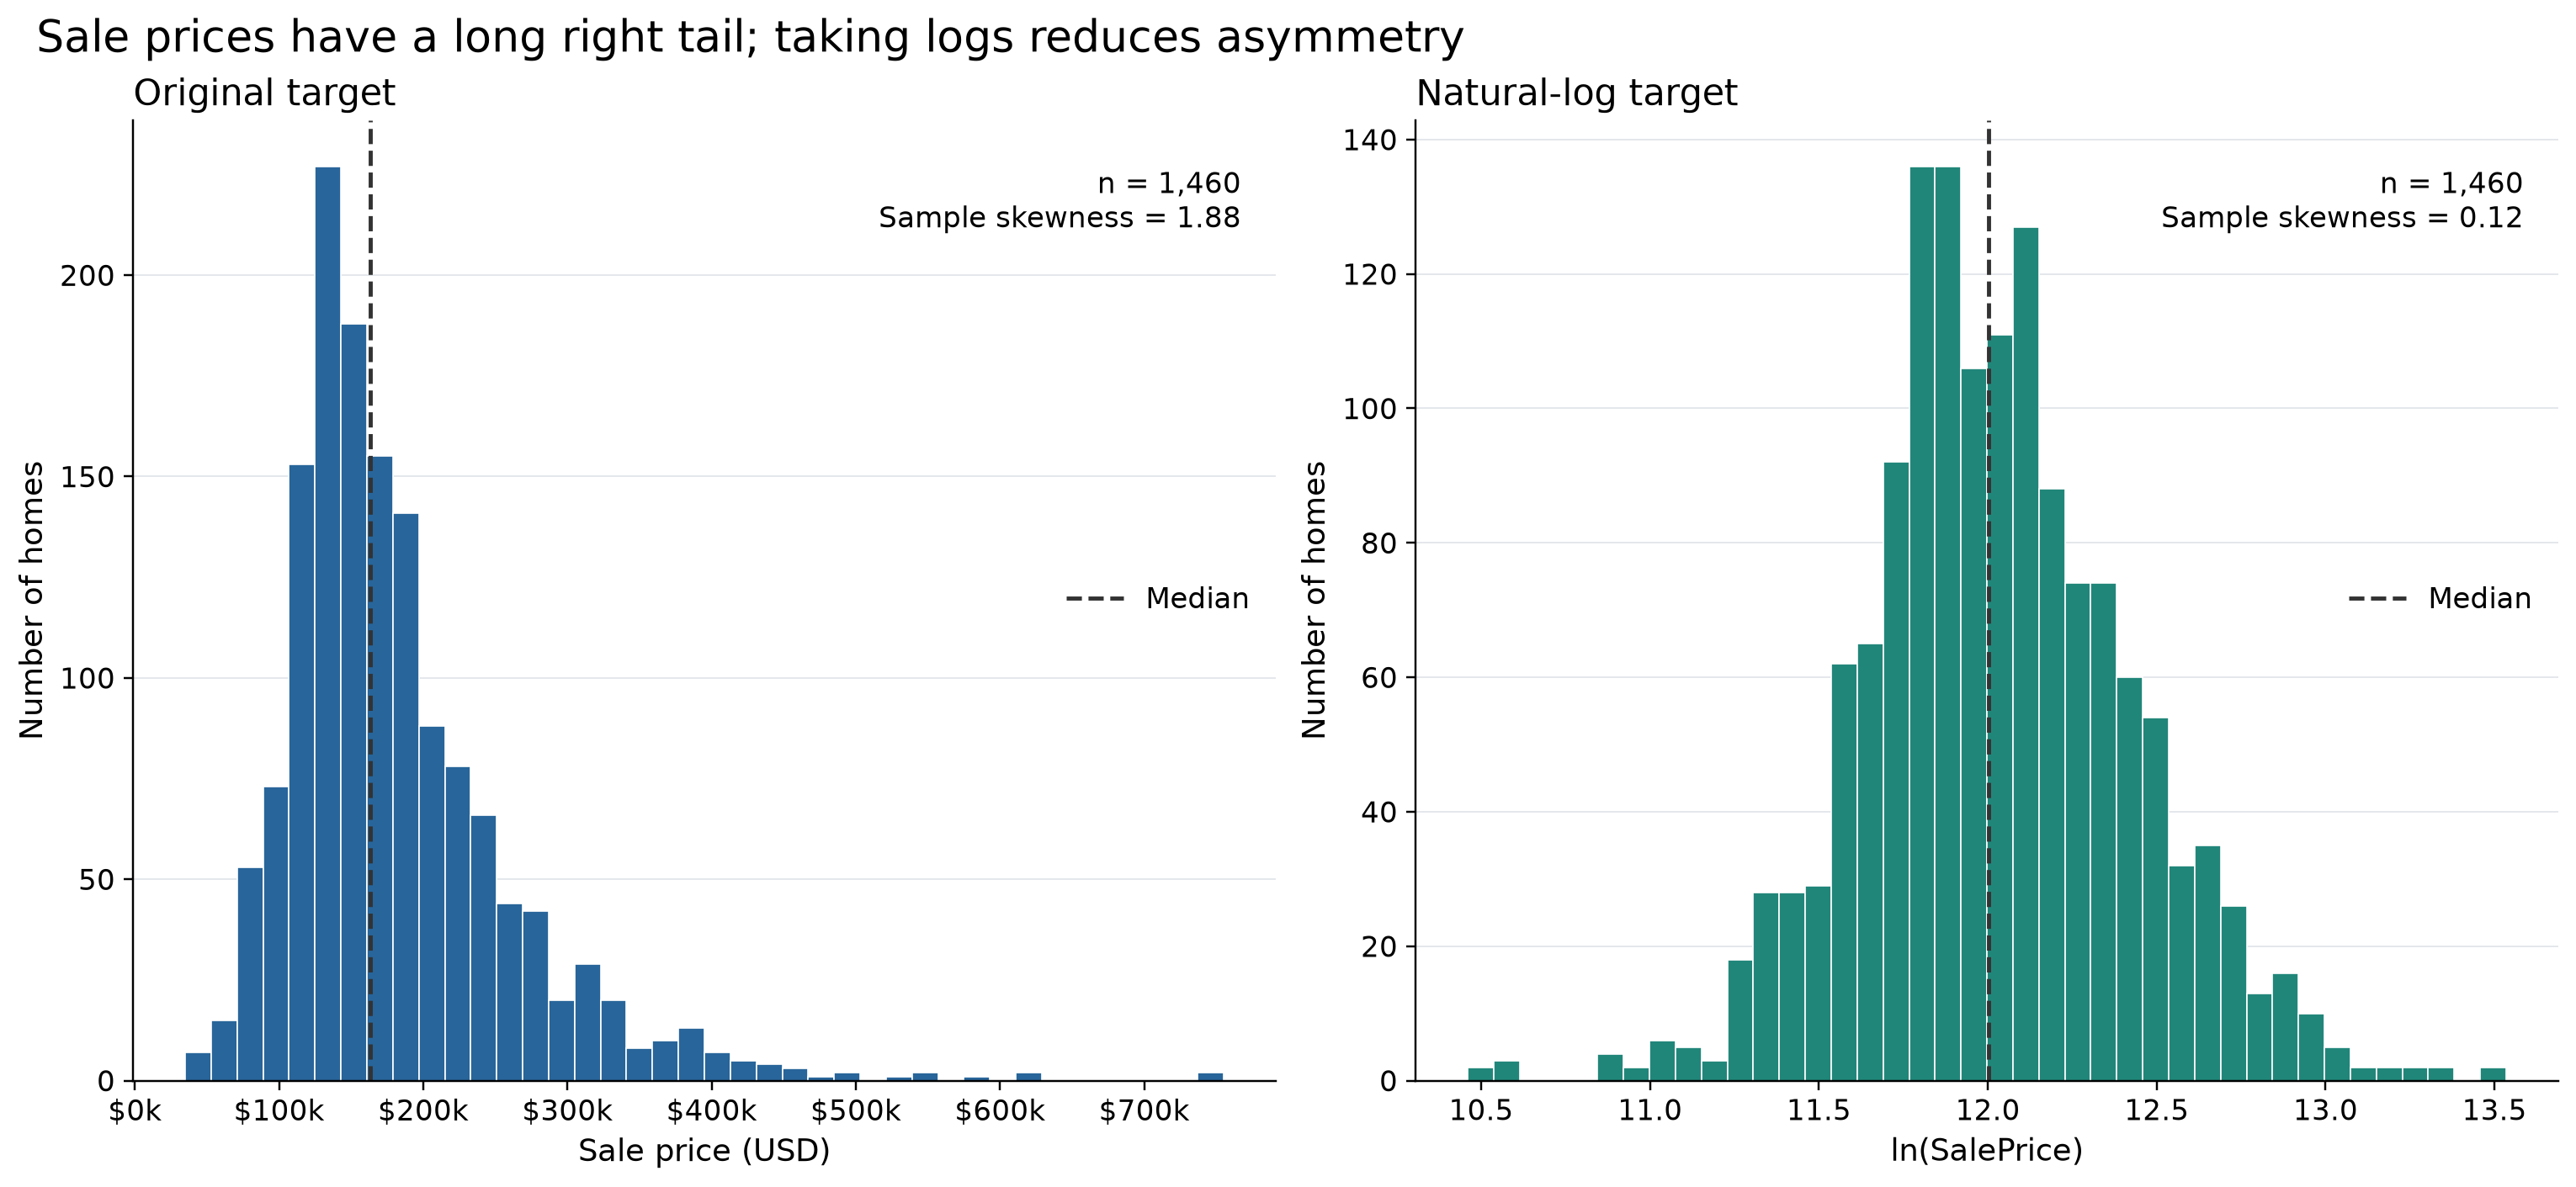

SalePrice in dollars and its natural logarithm, with 40 histogram bins and the sample median. Both panels retain all observations.

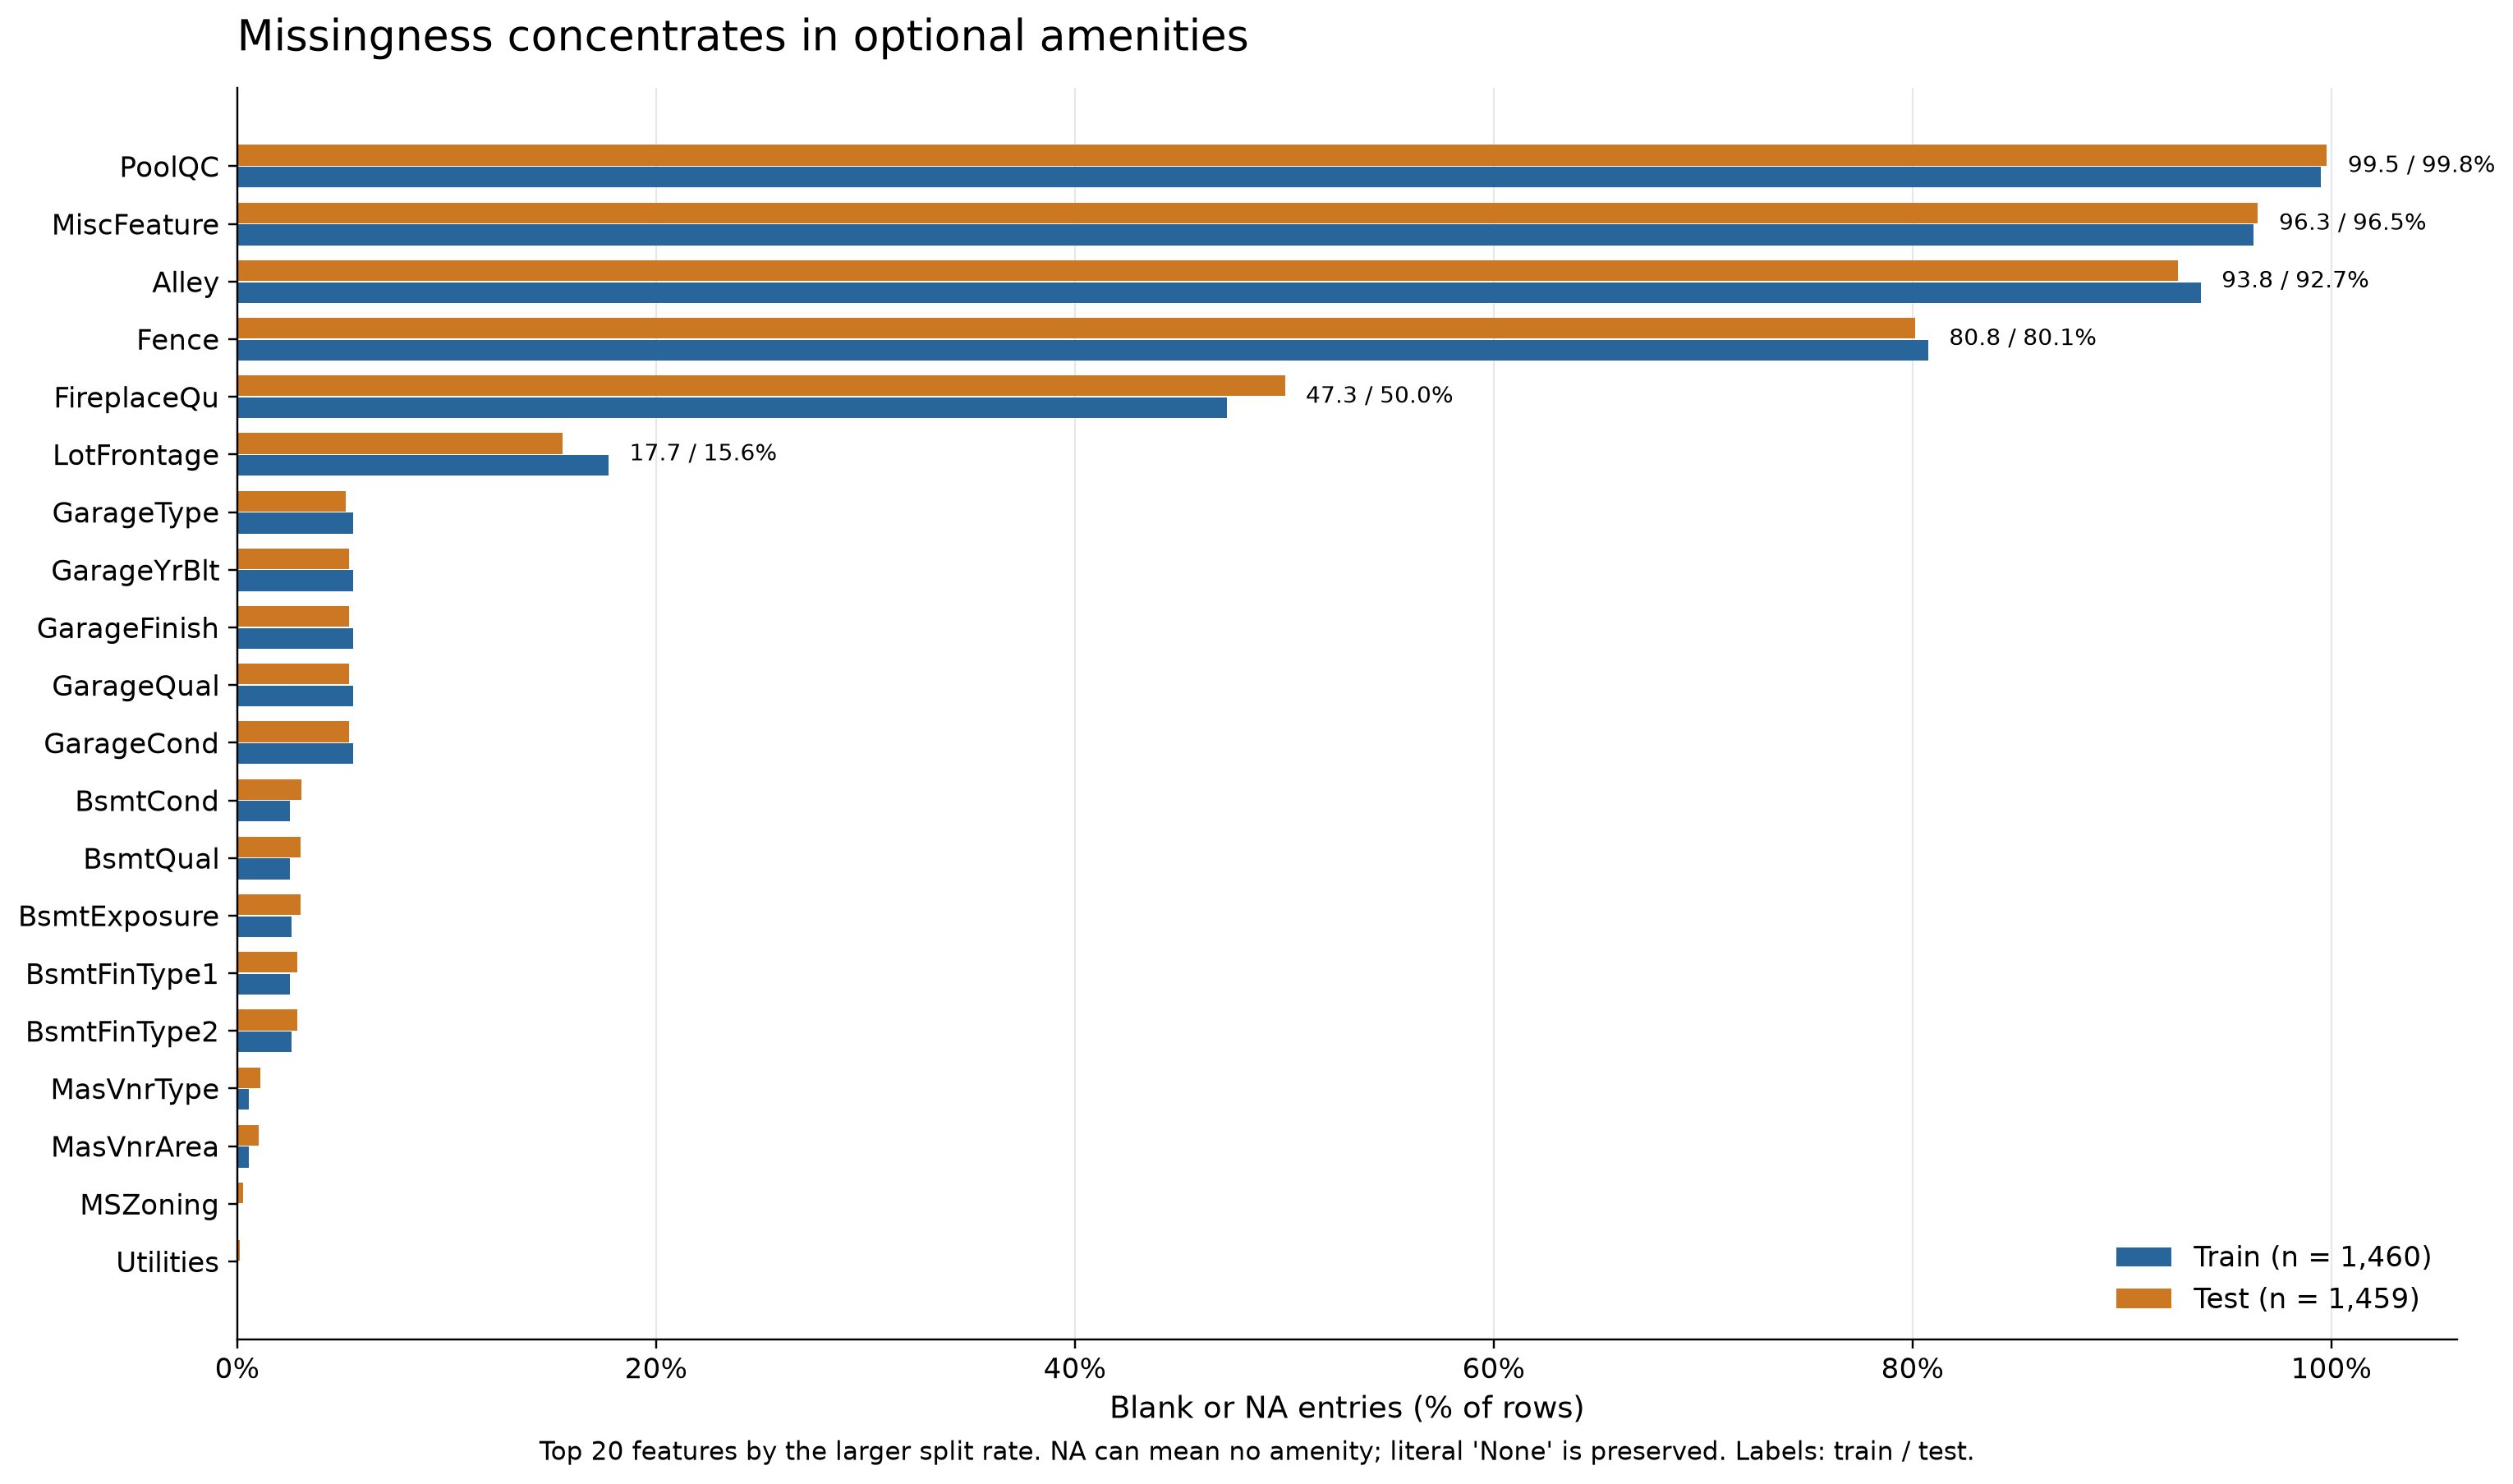

Top 20 features ranked by the larger train/test blank-or-NA percentage. The valid MasVnrType category None is not counted as missing. NA in amenity fields may represent structural absence.

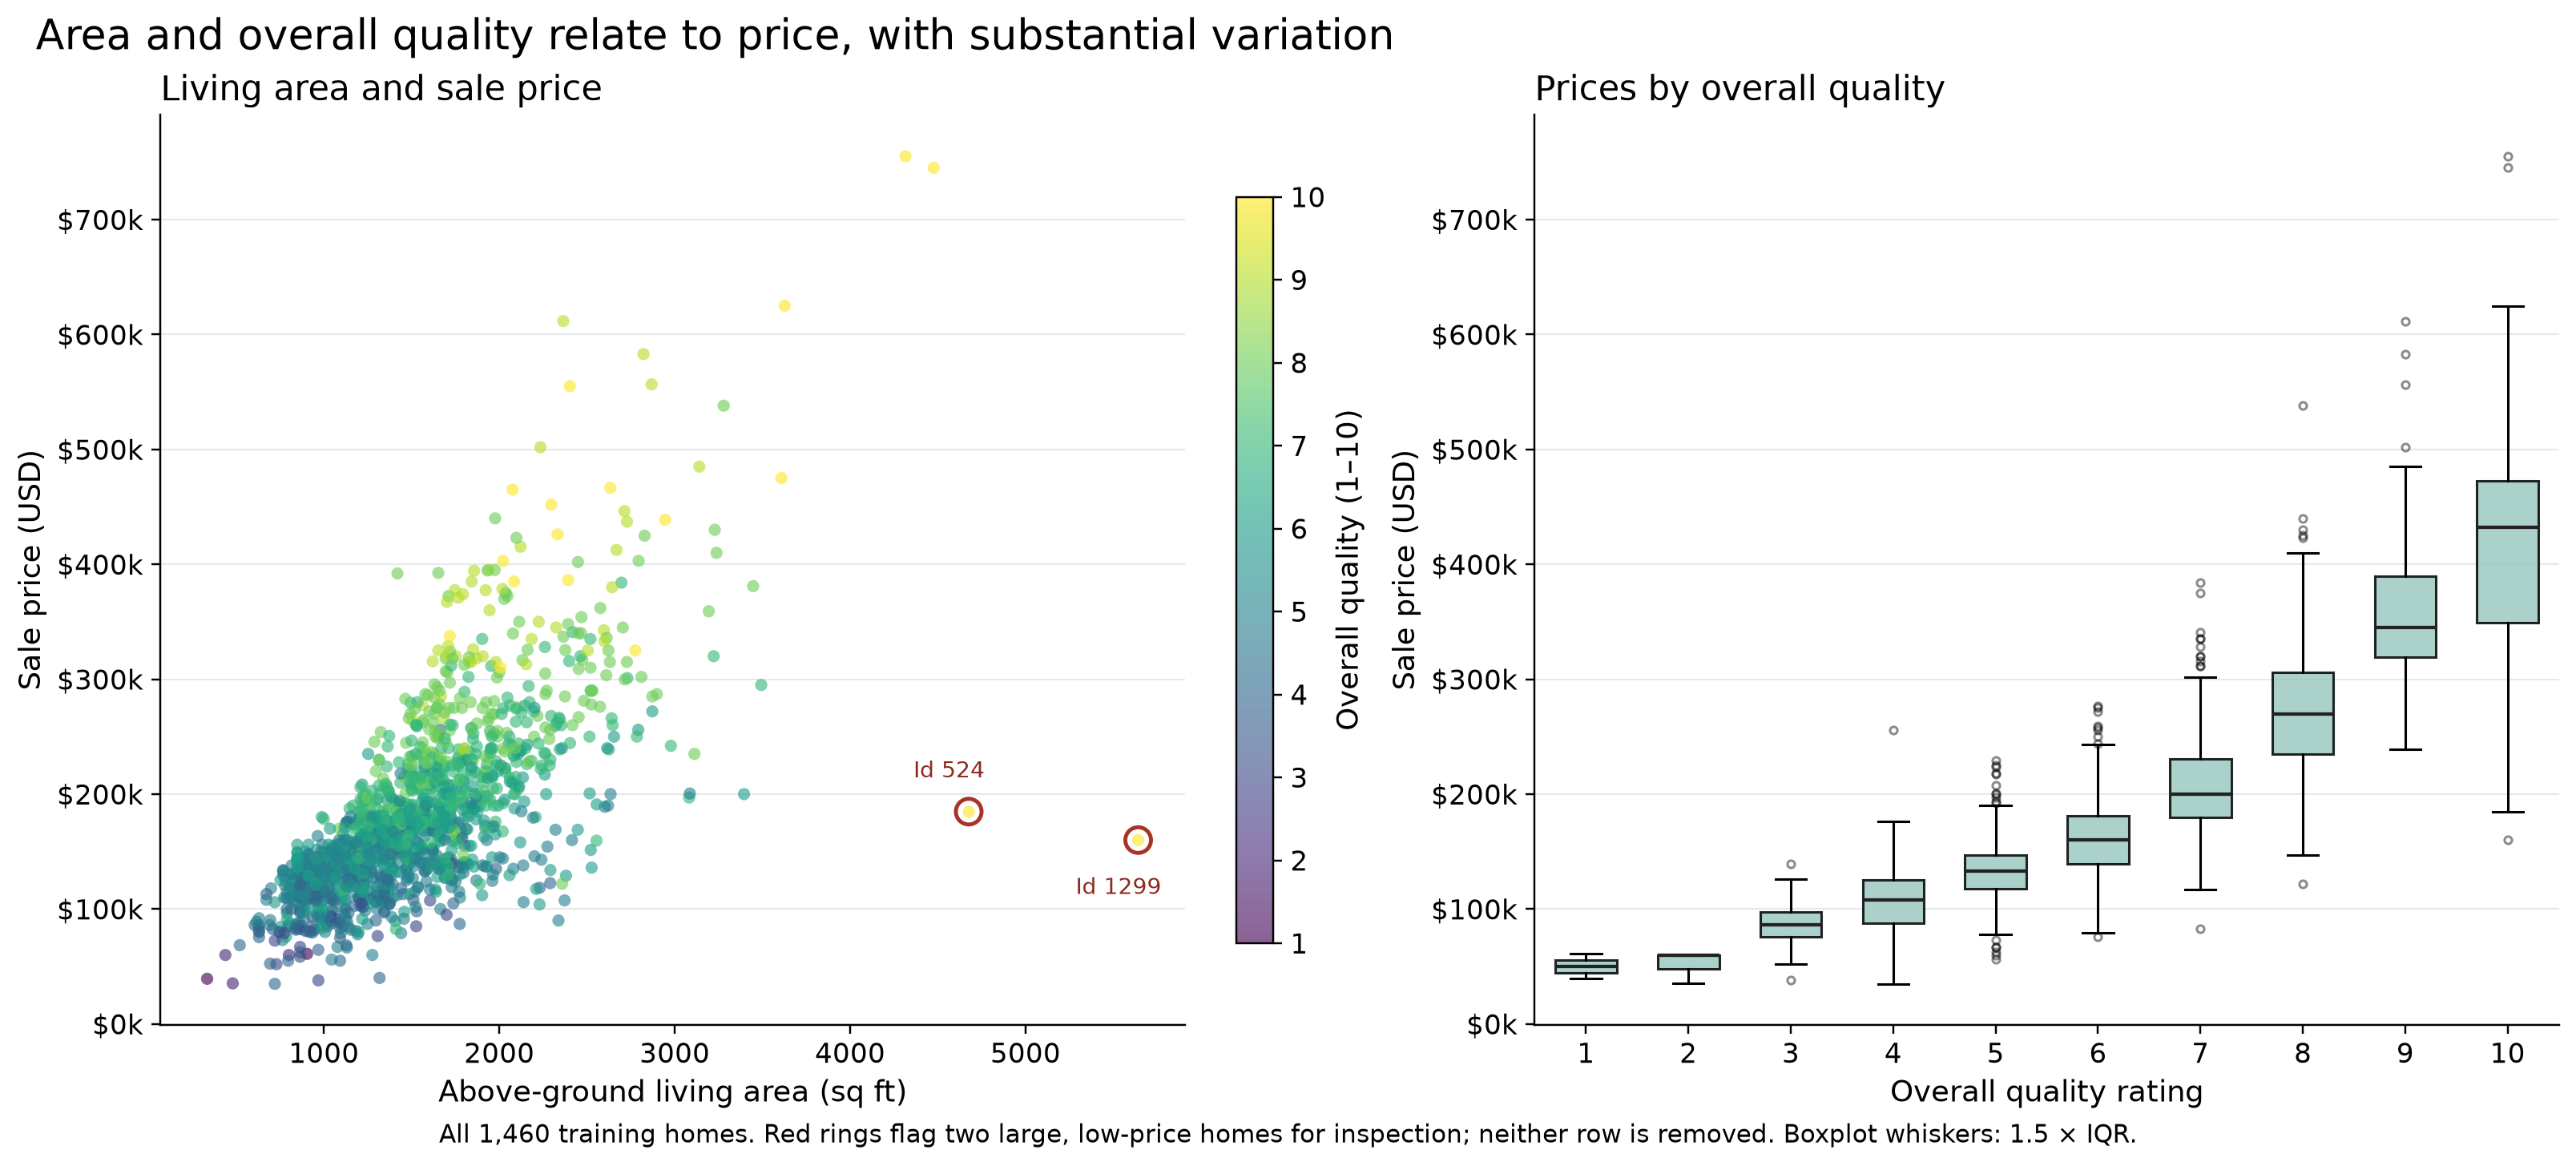

Living area versus SalePrice, coloured by quality, and quality-group boxplots. Id 524 and 1299 satisfy GrLivArea > 4000 and SalePrice < 300000. Both are retained; these descriptive associations do not establish causality.

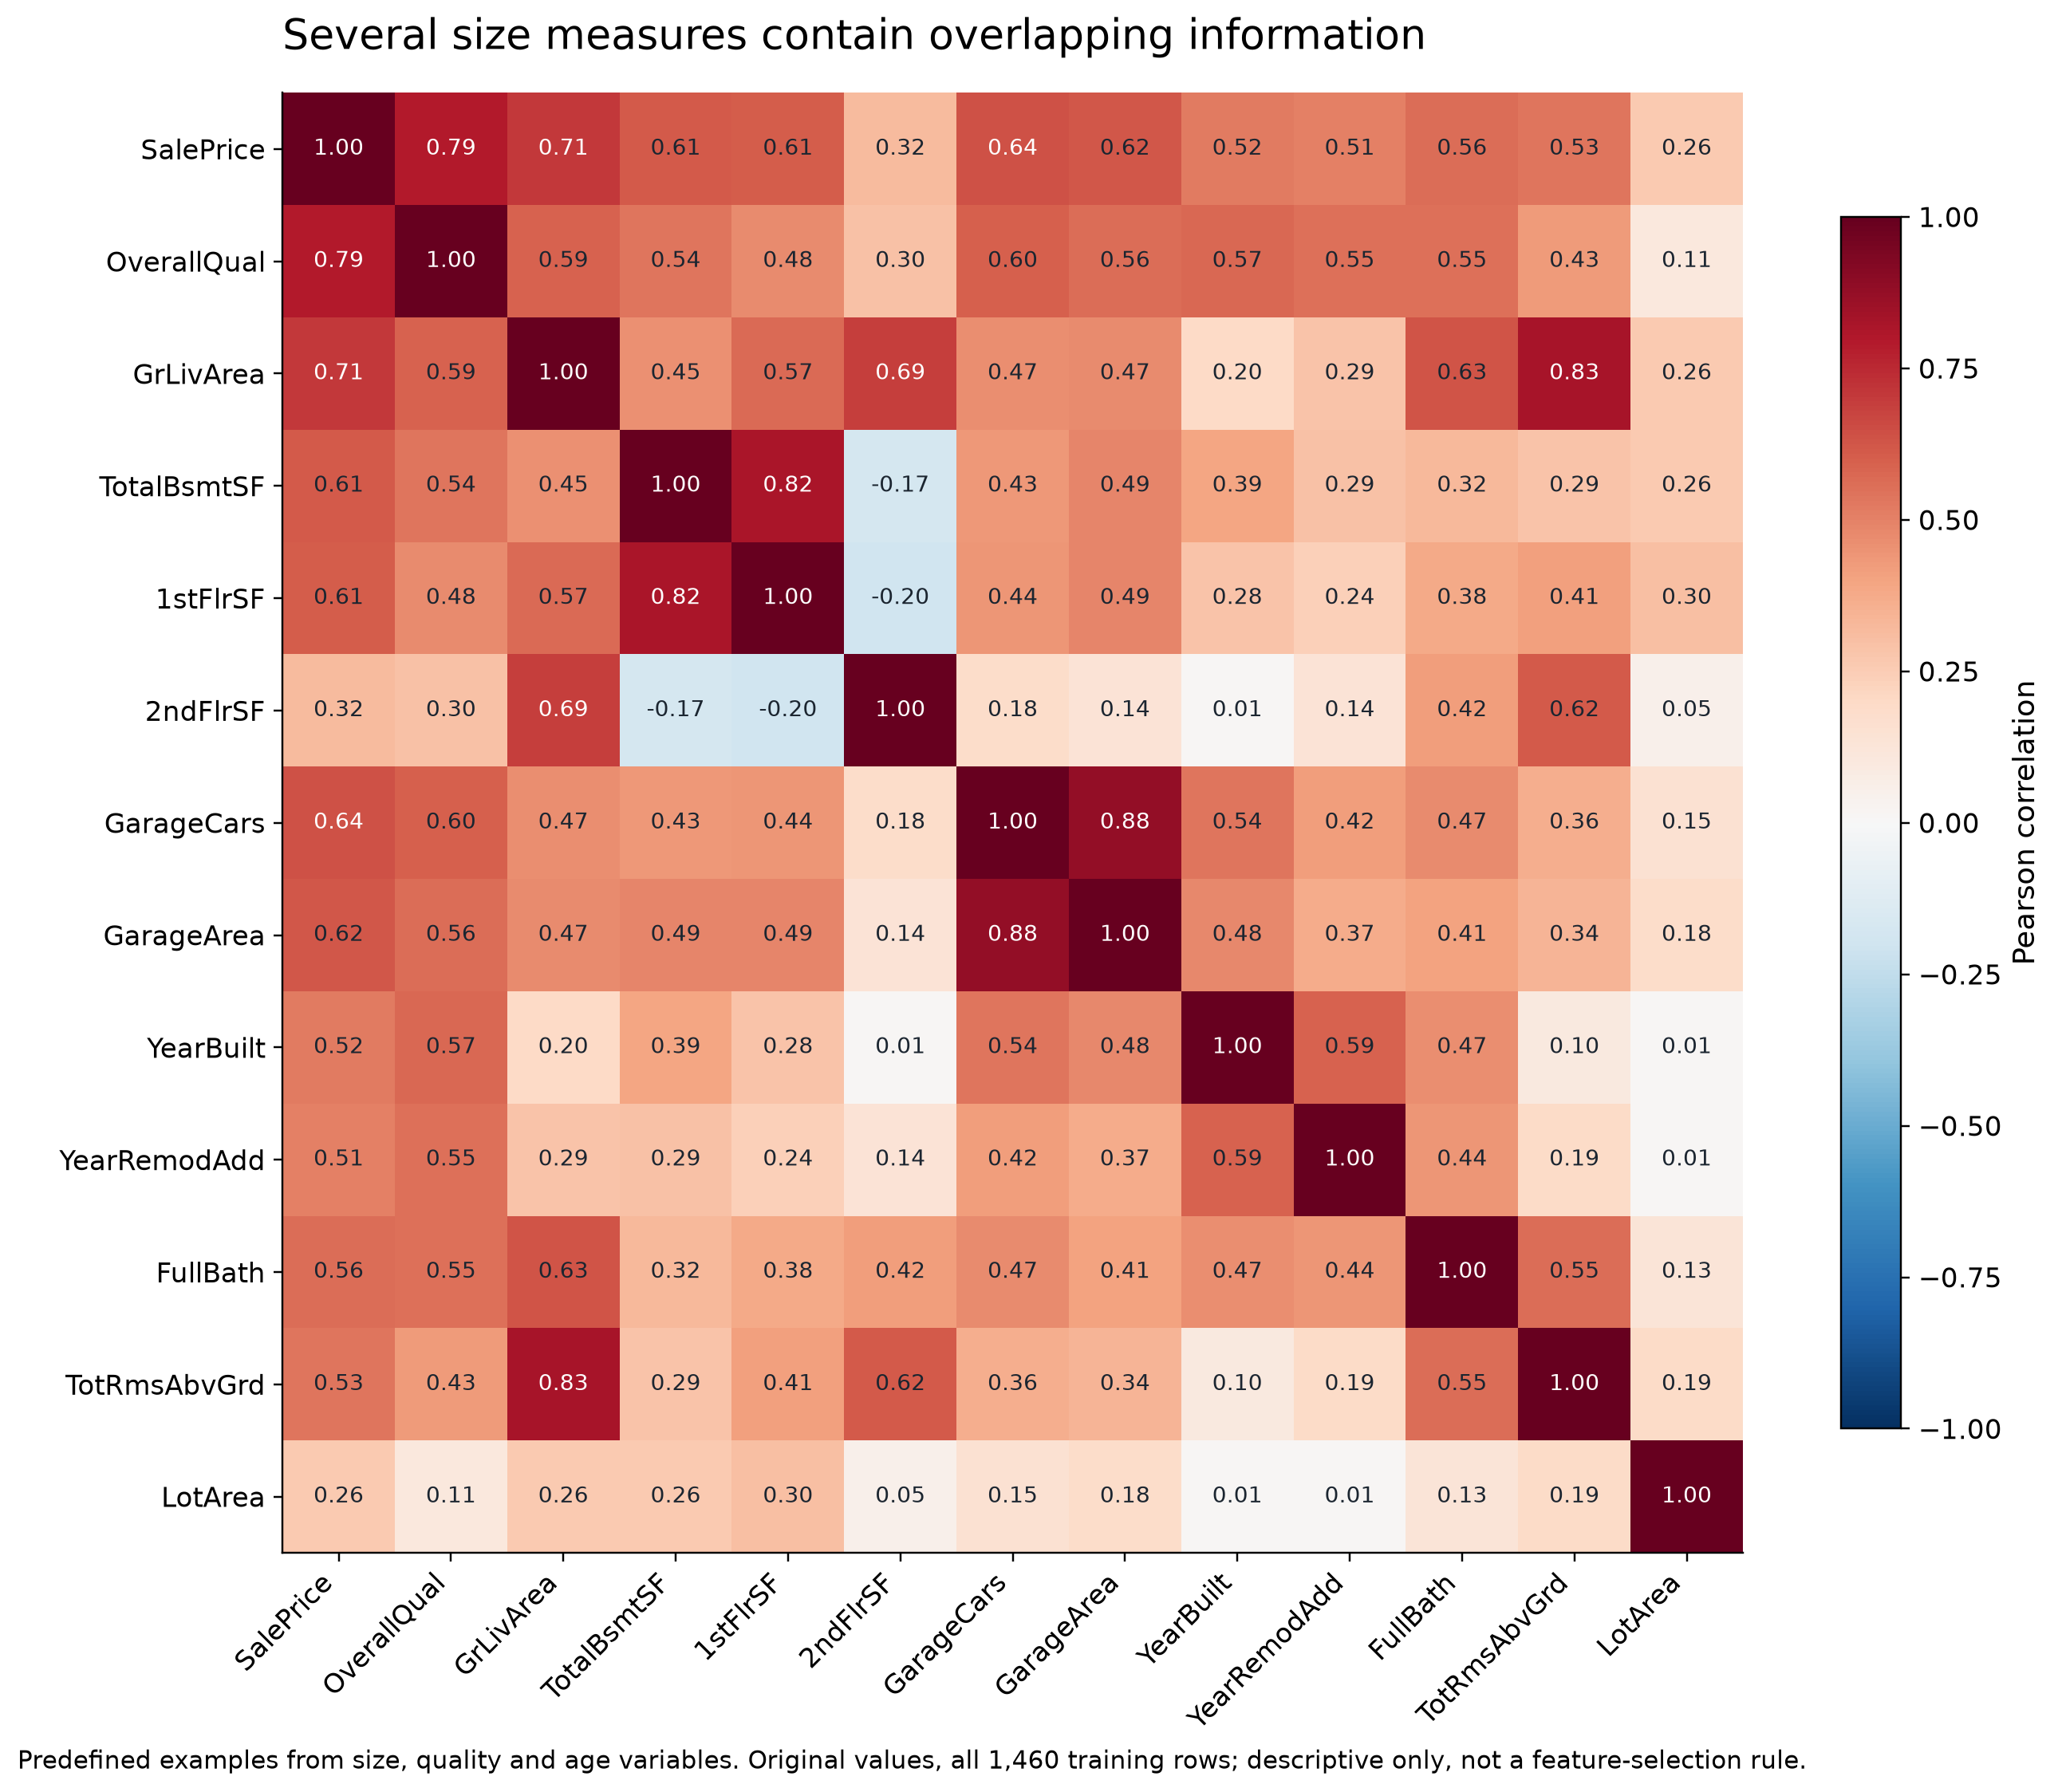

Pearson correlations on original-valued, predefined numeric examples. Correlations describe these numeric examples. Learned preprocessing and model comparisons use their recorded cross-validation partitions.

In [3]:
eda=json.loads((ROOT/'data/preprocessing/eda_summary.json').read_text())
assert eda['dataset']['train_rows']==len(train) and eda['dataset']['test_rows']==len(test)
assert eda['data_policy']['training_rows_removed']==0
for key,series in [('sale_price_usd',train.SalePrice),('ln_sale_price',np.log(train.SalePrice))]:
    measured={'count':series.count(),'mean':series.mean(),'std_sample':series.std(ddof=1),
              'minimum':series.min(),'q25':series.quantile(.25),'median':series.median(),
              'q75':series.quantile(.75),'maximum':series.max(),'skewness_sample':series.skew()}
    for name,value in measured.items():
        assert np.isclose(value,eda['target'][key][name],rtol=1e-12,atol=1e-12)
print('Saved EDA target statistics agree with all 1,460 original training rows.')
display(pd.DataFrame(eda['missingness']).head(12))
for item in eda['figures']:
    display(Image(filename=str(ROOT/'outputs/figures'/f"{item['stem']}.png"),width=900))
    display(Markdown(item['caption']))


### B.4 Deterministic feature handoff

The saved row-local feature exports are checked against the current preprocessing implementation. Learned imputation, scaling, transformation selection and category dictionaries must be fitted inside each training fold. The final raw TabPFN and TabICL branches consume their original 79 predictors; the domain TabPFN branch applies its own recorded feature map. The final model uses those component-specific input views.

In [4]:
display(Markdown('```python\n'+inspect.getsource(deterministic_features)+'\n```'))
X_A=deterministic_features(train.drop(columns='SalePrice'),semantic=False)
X_test_A=deterministic_features(test,semantic=False)
assert X_A.columns.tolist()==X_test_A.columns.tolist()
# Compare the saved handoff rather than rewriting it.
saved_train=read_data(ROOT/'data/preprocessing/train_processed.csv')
saved_test=read_data(ROOT/'data/preprocessing/test_processed.csv')
# CSV inference reads numeric-looking class codes as integers; the feature map
# deliberately treats them as categorical strings.
saved_train['MSSubClass']=saved_train.MSSubClass.astype(str)
saved_test['MSSubClass']=saved_test.MSSubClass.astype(str)
pd.testing.assert_frame_equal(X_A.assign(SalePrice=train.SalePrice),
    saved_train,check_dtype=False,check_exact=False,rtol=1e-12,atol=1e-12)
pd.testing.assert_frame_equal(X_test_A,saved_test,
    check_dtype=False,check_exact=False,rtol=1e-12,atol=1e-12)
print('Saved deterministic handoffs agree:',X_A.shape,X_test_A.shape)
print('Missing cells retained for fold-local processing:',int(X_A.isna().sum().sum()))


```python
def deterministic_features(X, semantic=False, groups=ALL_GROUPS):
    """Apply row-local rules only; no statistics, targets, or test-set fitting.

    Existing engineered columns are rebuilt so exported A-stage data is a valid
    input to every experiment, including experiments with no engineered groups.
    Missing component sizes are temporarily zero in derived sums; their original
    columns retain missing values for later fold-fitted imputation.
    """
    if "SalePrice" in X:
        raise ValueError("SalePrice must be separated before preprocessing.")
    out = X.drop(columns=ENGINEERED_COLUMNS, errors="ignore").copy()
    if "MSSubClass" in out:
        out["MSSubClass"] = out["MSSubClass"].map(
            lambda v: str(int(float(v))) if pd.notna(v) else np.nan
        ).astype(object)
    # pandas 3 string columns become ordinary object columns for sklearn.
    for c in out.select_dtypes(include=["string", "object"]).columns:
        out[c] = out[c].astype(object).where(out[c].notna(), np.nan)

    def num(c):
        return pd.to_numeric(out[c], errors="coerce").fillna(0.0)

    if semantic:
        for c in ["Alley", "Fence"]:
            out[c] = out[c].fillna("None")
        for columns, presence in [
            (["PoolQC"], num("PoolArea") > 0),
            (["FireplaceQu"], num("Fireplaces") > 0),
            (["MiscFeature"], num("MiscVal") > 0),
            (["GarageType", "GarageFinish", "GarageQual", "GarageCond"], num("GarageCars") > 0),
            (["BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"], num("TotalBsmtSF") > 0),
            (["MasVnrType"], num("MasVnrArea") > 0),
        ]:
            for c in columns:
                out[c] = out[c].fillna(pd.Series(np.where(presence, "Unknown", "None"), index=out.index))
        # Size missingness remains available as an explicit indicator.
        for c in ["MasVnrArea", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath", "BsmtHalfBath", "GarageCars", "GarageArea"]:
            out[c + "Missing"] = out[c].isna().astype(int)
            out[c] = out[c].fillna(0.0)
    total_sf = num("TotalBsmtSF") + num("1stFlrSF") + num("2ndFlrSF")
    if "area" in groups:
        out["TotalSF"] = total_sf
        out["TotalFinishedSF"] = num("GrLivArea") + num("BsmtFinSF1") + num("BsmtFinSF2")
    if "age" in groups:
        out["HouseAge"] = (num("YrSold") - num("YearBuilt")).clip(lower=0)
        out["RemodelAge"] = (num("YrSold") - num("YearRemodAdd")).clip(lower=0)
        out["GarageAge"] = (num("YrSold") - num("GarageYrBlt")).clip(lower=0).where(num("GarageYrBlt") > 0, 0)
        out["WasRemodeled"] = (num("YearRemodAdd") != num("YearBuilt")).astype(int)
    if "baths" in groups:
        out["TotalBath"] = num("FullBath") + 0.5 * num("HalfBath") + num("BsmtFullBath") + 0.5 * num("BsmtHalfBath")
    if "porch" in groups:
        out["TotalPorchSF"] = sum(num(c) for c in ["OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch", "WoodDeckSF"])
    if "quality" in groups:
        out["QualityLivingArea"] = num("OverallQual") * num("GrLivArea")
        out["QualityTotalSF"] = num("OverallQual") * total_sf
    return out

```

Saved deterministic handoffs agree: (1460, 90) (1459, 90)
Missing cells retained for fold-local processing: 6965


### B.5 Selected model and prediction settings

The selected model is **R6ICL_anchor80_tabicl20**, a fixed TabPFN/TabICLv2 blend with an observed Kaggle score of **0.10970**. Let $f_A$, $f_B$ and $f_C$ return predicted natural-log prices from the raw noY TabPFN, domain TabPFN and TabICL branches. Its prediction is

$$
\begin{aligned}
\widehat z(x)&=0.64f_A(x)+0.16f_B(\phi(x))+0.20f_C(x),\\
\widehat y(x)&=\exp(\widehat z(x)).
\end{aligned}
$$

The coefficients apply to every house and expand the implemented nested 80/20 blends. This is a weighted geometric mean in dollar space.

| Leaf | Raw noY TabPFN | Domain TabPFN | TabICLv2 |
| --- | --- | --- | --- |
| Input columns, excluding Id | 79 original | 98: 79 original + 10 engineered + 9 missing flags | 79 original |
| Inference members | 16 across three v2 checkpoints, allocated 6/5/5 | 32 using one v2 checkpoint | 8 using one v2 regression checkpoint |
| Supplied target | Natural-log SalePrice | Natural-log SalePrice | Natural-log SalePrice |
| Additional target power map | Disabled; standardization remains | Identity and safe-power | StandardScaler on supplied log target |
| Final log weight | 0.64 | 0.16 | 0.20 |

The TabPFN leaves use package 9.2.0 and original-v2 weights. TabICL uses package 2.2.0, the official v2 regression checkpoint, seed 42, none/power normalization views, Latin feature permutations and output_type="mean". The executed configuration uses MPS, use_amp=False, use_fa3=False and 12 Torch threads. The released checkpoints use training-partition transformations and labeled in-context examples [1,2].

The deterministic map $\phi$ constructs area, age, bathroom, porch and quality summaries without target statistics. Learned encoding, scaling and model preprocessing use only the training partition. Five-fold validation covers all **1,460** houses, with **1,168** training and **292** held-out rows per fold. Final predictions cover all **1,459** test houses in their original Id order.

The selected model has seed-42 mean-fold log RMSE **0.115308212**, fold SD **0.021422484** and pooled OOF RMSE **0.116889358**. Development results and leaderboard feedback informed model selection.

Recombining saved leaf predictions verifies the formula within floating-point precision.

The model, input data and evidence are identified by hashes. Historical candidate comparisons and their raw records remain in the repository data folders; this section describes the selected final model.

#### Algorithm references

[1] Hollmann, N., et al.. Accurate predictions on small data with a tabular foundation model. Nature, 637, 319-326. https://doi.org/10.1038/s41586-024-08328-6

[2] Qu, J., et al.. TabICLv2: A better, faster, scalable, and open tabular foundation model. https://arxiv.org/abs/2602.11139

[3] Official implementations and prediction APIs: https://github.com/PriorLabs/TabPFN/tree/v9.2.0 and https://github.com/soda-inria/tabicl

Built with PriorLabs-TabPFN and TabICL. Checkpoint licenses and source hashes accompany the project.


### B.6 Generate predictions

The next cell runs the final three-component algorithm and writes `outputs/predictions.csv` inside the prepared workspace. Its inputs are the saved predictions of the fitted raw TabPFN, domain TabPFN and TabICL components. Numerical reconstruction is checked to 1e-12 in log price. Run `python code/ensemble/model.py export` from the workspace root to copy the exact scored CSV to `outputs/scored_submission.csv`.

Run this cell from the prepared Notebook workspace described at the start.


In [5]:
# Execute the selected model's prediction arithmetic from the canonical module.
model_spec=importlib.util.spec_from_file_location('notebook_ensemble_model',ROOT/'code/ensemble/model.py')
model=importlib.util.module_from_spec(model_spec)
model_spec.loader.exec_module(model)
config=model.load_config()
assert config['submission']['experiment_id']=='R6ICL_anchor80_tabicl20'
display(Markdown('```python\n'+inspect.getsource(model.predict)+'\n```'))
prediction=model.predict('outputs/predictions.csv')
generated=pd.read_csv(prediction['output'])
test_ids=pd.read_csv(ROOT/'data/raw/test.csv',usecols=['Id']).Id
assert generated.Id.equals(test_ids) and generated.shape==(1459,2)
assert np.isfinite(generated.SalePrice).all() and generated.SalePrice.gt(0).all()
# Independently evaluate the same expanded three-component formula.
leaf_logs={item['key']:pd.read_csv(ROOT/item['path']).log_prediction.to_numpy()
           for item in config['components']}
expected=sum(item['weight']*leaf_logs[item['key']] for item in config['components'])
np.testing.assert_allclose(np.log(generated.SalePrice),expected,rtol=0,atol=1e-12)
display(generated.head())
display({**{key:prediction[key] for key in ['rows','max_absolute_log_difference',
         'byte_identical_to_scored_csv','new_output_public_score']},'tolerance':1e-12})
print('Recomputed predictions:',Path(prediction['output']).relative_to(ROOT).as_posix())
print('The exact uploaded bytes have the recorded Kaggle score. Use python code/ensemble/model.py export for those bytes.')
current_path=ROOT/'data/overview/metadata/current_leaderboard.json'
if current_path.is_file():
    current=json.loads(current_path.read_text())
    display({'Recorded Kaggle score':current['best_score'],'Recorded rank':current['rank']})


```python
def predict(output="outputs/predictions.csv"):
    config = load_config()
    ids, combined, difference = prediction_sources(config)
    prices = [math.exp(v) for v in combined]
    require(all(math.isfinite(v) and v > 0 for v in prices), "Invalid recomputed price")
    stream = io.StringIO(newline="")
    writer = csv.writer(stream, lineterminator="\n")
    writer.writerow(["Id", "SalePrice"])
    writer.writerows(zip(ids, prices))
    path = write_output(stream.getvalue().encode("utf-8"), output)
    return {"status": "recomputed_from_saved_components", "output": str(path), "rows": len(ids),
            "max_absolute_log_difference": difference, "operation": "saved_prediction_blend",
            "byte_identical_to_scored_csv": sha256(path) == config["submission"]["sha256"],
            "new_output_public_score": None}

```

,Id,SalePrice
0,1461,128198.040774
1,1462,159695.183780
2,1463,188040.464494
3,1464,195918.049171
4,1465,181918.855725


{'rows': 1459,
 'max_absolute_log_difference': 5.329070518200751e-15,
 'byte_identical_to_scored_csv': False,
 'new_output_public_score': None,
 'tolerance': 1e-12}

Recomputed predictions: outputs/predictions.csv
The exact uploaded bytes have the recorded Kaggle score. Use python code/ensemble/model.py export for those bytes.


{'Recorded Kaggle score': 0.1097, 'Recorded rank': 104}

### B.7 Validate the final model result

The next two cells validate the final scored predictions and receipt, then independently recompute this model’s five-fold validation metrics.

Leaderboard positions are recorded snapshots. The displayed rank comes from the retained leaderboard record.


In [6]:
summary=json.loads((ROOT/'data/overview/summary.json').read_text())
ledger=json.loads((ROOT/'data/overview/kaggle_submissions.json').read_text())
assert summary['best_experiment']=='R6ICL_anchor80_tabicl20' and ledger['best_observed_score']==0.10970
final_path=ROOT/'data/iteration_06/selected/submission.csv'
assert hashlib.sha256(final_path.read_bytes()).hexdigest()=='799c2a553735fe49989fdf6cb1eb3869a28a2898fc03171e6a008d0ab55acaf8'
final=pd.read_csv(final_path)
test_ids=pd.read_csv(ROOT/'data/raw/test.csv',usecols=['Id']).Id
assert final.shape==(1459,2) and final.columns.tolist()==['Id','SalePrice'] and final.Id.equals(test_ids)
assert np.isfinite(final.SalePrice).all() and final.SalePrice.gt(0).all()
receipt=next(row for row in ledger['submissions'] if row['experiment_id']==summary['best_experiment'])
assert receipt['status']=='complete' and receipt['public_score']==0.10970
assert recorded_file(receipt['file_sha256']).read_bytes()==final_path.read_bytes()
assert recorded_file(receipt['screenshot_sha256']).is_file()
display(pd.DataFrame([{'Model':'Final TabPFN/TabICL blend',
    'Mean CV log RMSE':summary['best_cv_mean'],
    'Fold standard deviation':summary['best_cv_std'],
    'Pooled OOF log RMSE':summary['best_pooled_oof_log_rmse'],
    'Recorded Kaggle score':ledger['best_observed_score']}]))
print('Final scored CSV and its submission receipt agree. Original scored bytes are unchanged.')


,Model,Mean CV log RMSE,Fold standard deviation,Pooled OOF log RMSE,Recorded Kaggle score
0,Final TabPFN/TabICL blend,0.115308,0.021422,0.116889,0.1097


Final scored CSV and its submission receipt agree. Original scored bytes are unchanged.


In [7]:
# Recompute the selected final model's validation metrics from its saved OOF predictions.
train_labels=pd.read_csv(ROOT/'data/raw/train.csv',usecols=['Id','SalePrice'])
scores=pd.read_csv(ROOT/'data/overview/experiment_results.csv')
scores=scores.loc[scores.experiment_id==summary['best_experiment']].reset_index(drop=True)
oof=pd.read_csv(ROOT/'data/overview/oof_predictions.csv')
folds=pd.read_csv(ROOT/'data/overview/fold_assignments.csv')
assert len(scores)==1
assert len(oof)==1460 and oof.Id.equals(train_labels.Id) and folds.Id.equals(train_labels.Id)
assert set(folds.fold)=={1,2,3,4,5} and folds.fold.value_counts().eq(292).all()
columns=[name+'__log_prediction' for name in scores.experiment_id]
values=oof[columns].to_numpy(float)
assert np.isfinite(values).all()
squared=(values-np.log(train_labels.SalePrice.to_numpy())[:,None])**2
fold_rmse=np.stack([np.sqrt(squared[folds.fold==k].mean(axis=0)) for k in range(1,6)])
np.testing.assert_allclose(fold_rmse.mean(axis=0),scores.cv_mean,rtol=0,atol=1e-12)
np.testing.assert_allclose(fold_rmse.std(axis=0,ddof=1),scores.cv_std,rtol=0,atol=1e-12)
np.testing.assert_allclose(np.sqrt(squared.mean(axis=0)),scores.pooled_oof_log_rmse,rtol=0,atol=1e-12)
display(pd.DataFrame({'Fold':range(1,6),'Final model log RMSE':fold_rmse[:,0]}))
print('Final-model CV mean, sample standard deviation and pooled OOF error agree with the recorded result.')


,Fold,Final model log RMSE
0,1,0.118204
1,2,0.101211
2,3,0.151064
3,4,0.107961
4,5,0.098101


Final-model CV mean, sample standard deviation and pooled OOF error agree with the recorded result.


### B.8 Interpreting the saved checks

These checks identify the original inputs, verify the selected prediction formula and summarize the original evaluation results.

| Notebook check | Interpretation |
| --- | --- |
| Data and feature handoff | Recorded hashes and row-local feature checks identify the exact inputs; learned transformations remain fitted inside training folds. |
| Saved blend calculation | The three saved log predictions reproduce the final weighted formula to floating-point precision. |
| OOF and scored artifact | Fold metrics use held-out training houses. The 0.10970 Kaggle score belongs to the preserved submitted CSV; recomputed files remain separate. |

Each OOF row excludes its own label from fitting, whereas the final test predictions use the full labeled context. The validation metrics and submission checks therefore serve different purposes even when they share the same blend weights.
